# 03 Ingeniería de características y transformación

- Entrada: `data/processed/austin_animal_center_clean.csv` (salida del notebook 02)
- Salida: `data/processed/dev_features.csv` y `build_preprocessor` (en `notebooks/features.py`)

Solo se usa información conocida al ingreso. Las columnas de salida solo sirven para construir los objetivos.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

from config import SEED
from features import (FEATURES, BINARY, CAT_LOW, CAT_HIGH, NUMERIC,
                      add_features, make_targets, build_preprocessor)

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/processed/austin_animal_center_clean.csv")
print(df.shape)
feats = add_features(df)

(63681, 13)


## 1. Variables nuevas

Se crean desde las 13 columnas limpias. Cada una responde a algo visto en el EDA.

| Variable | Origen | Motivo |
|---|---|---|
| `is_mix`, `is_crossbreed`, `breed_main` | `breed` | 1 946 razas. Se separa mestizo, cruce y raza principal (sin `Mix`). |
| `color_main`, `is_bicolor`, `is_tabby` | `color` | 488 colores. Primer color y dos rasgos. |
| `city`, `has_location_detail` | `found_location` | Miles de direcciones. Se queda la ciudad y si hay dirección. |
| `sex`, `is_neutered` | `sex_upon_intake` | Sexo (`Male`, `Female`, `Unknown`) y si está esterilizado (1/0). Si el sexo es `Unknown`, `is_neutered` es 0. |
| `age_days`, `is_baby` | `age_upon_intake_(days)` | Los cachorros se adoptan distinto. |
| `condition_serious` | `intake_condition` | `Sick` e `Injured` terminan más en eutanasia. |
| `prior_stays` | `animal_id_intake`, `intake_datetime` | Ingresos anteriores del mismo animal, contados por fecha. No se usa `intake_number` porque no sigue el orden por fecha. |
| `hour`, `month`, `weekday`, `season`, `t_months` | `intake_datetime` | Estacionalidad y tendencia (meses desde 2013). |

`animal_id_intake` no es variable: solo se usa para agrupar al validar.

In [10]:
print("Nulos en las variables:", feats[FEATURES].isna().sum().sum())
print(feats[CAT_LOW + CAT_HIGH].nunique().to_string())

Nulos en las variables: 0
animal_type           4
intake_type           5
intake_condition      8
sex                   3
weekday               7
season                4
breed_main          329
color_main           58
city                 26


## 2. ¿Tienen relación con los resultados?

Para cada grupo se muestra el % de cada resultado (clasificación) y la mediana de días hasta la adopción, solo entre adoptados (regresión). Si los grupos se parecen, la variable aporta poco.

In [11]:
y = make_targets(df)
data = feats.join(y)
data["prior_stays (0, 1, 2+)"] = data["prior_stays"].clip(upper=2)
classes = ["Adoption", "Transfer", "Return to Owner", "Euthanasia", "Other"]

rows = []
for col in BINARY + ["sex", "prior_stays (0, 1, 2+)"]:
    for value, g in data.groupby(col):
        row = {"variable": col, "valor": value, "n": len(g)}
        row.update((g["y_outcome"].value_counts(normalize=True) * 100).reindex(classes, fill_value=0).round(1))
        row["mediana días"] = round(g.loc[g["y_outcome"] == "Adoption", "time_in_shelter_days"].median(), 1)
        rows.append(row)
pd.DataFrame(rows).set_index(["variable", "valor"])

n  Adoption  Transfer  Return to Owner  \
variable               valor                                                 
is_neutered            0        44634      44.3      34.2             10.3   
                       1        19047      38.4      19.7             37.6   
is_mix                 0        10181      41.2      20.9             24.7   
                       1        53500      42.8      31.6             17.3   
is_crossbreed          0        57748      41.6      30.9             17.8   
                       1         5933      51.8      20.4             24.8   
is_bicolor             0        30166      40.0      34.1             14.8   
                       1        33515      44.8      26.1             21.7   
is_tabby               0        52756      42.3      26.6             21.3   
                       1        10925      43.4      45.7              4.7   
has_location_detail    0        14102      51.6      27.1             15.9   
                       1        49579      39.9      30.7             19.2   
is_baby                0        36973      36.1      24.8             28.0   
                       1        26708      51.4      37.0              5.3   
condition_serious      0        56259      45.3      29.4             19.7   
                       1         7422      21.7      33.4              8.7   
sex                    Female   27907      48.2      30.0             17.6   
                       Male     30346      44.7      27.9             22.3   
                       Unknown   5428       1.0      40.2              1.3   
prior_stays (0, 1, 2+) 0        57564      42.0      31.3             16.9   
                       1         4826      48.6      17.3             30.7   
                       2         1291      40.8      13.5             43.8   

                                Euthanasia  Other  mediana días  
variable               valor                                     
is_neutered            0               9.5    1.7          10.2  
                       1               3.9    0.4          10.9  
is_mix                 0              11.7    1.5           7.1  
                       1               7.1    1.3          11.2  
is_crossbreed          0               8.4    1.4          11.1  
                       1               2.7    0.3           7.0  
is_bicolor             0               9.4    1.7          12.1  
                       1               6.5    1.0           9.2  
is_tabby               0               8.5    1.3           9.0  
                       1               4.8    1.4          23.1  
has_location_detail    0               4.8    0.7           9.3  
                       1               8.7    1.5          10.9  
is_baby                0              10.1    1.1          11.0  
                       1               4.8    1.6          10.0  
condition_serious      0               4.6    0.9           9.3  
                       1              32.0    4.1          40.1  
sex                    Female          3.5    0.7          10.2  
                       Male            4.2    0.8          10.4  
                       Unknown        50.3    7.1           4.9  
prior_stays (0, 1, 2+) 0               8.4    1.4          10.9  
                       1               3.1    0.3           7.3  
                       2               1.8    0.2          13.0

- `sex = Unknown`: 50,3 % `Euthanasia` y solo 1,0 % `Adoption`. `is_neutered = 0` mezcla animales intactos y `Unknown`, así que debe usarse siempre junto a `sex`.
- `condition_serious`: `Euthanasia` 32,0 % frente a 4,6 %. Los adoptados tardan 40,1 días frente a 9,3.
- `is_neutered`: `Return to Owner` 37,6 % si está esterilizado frente a 10,3 % si no.
- `is_baby`: `Return to Owner` 5,3 % frente a 28,0 %, y `Transfer` 37,0 % frente a 24,8 %.
- `is_tabby`: `Transfer` 45,7 % frente a 26,6 %. Los adoptados tardan 23,1 días frente a 9,0.
- `prior_stays`: con 2 o más ingresos previos, `Return to Owner` sube a 43,8 % (16,9 % sin ingresos previos).
- `is_weekend` se quitó: no cambiaba ningún resultado (diferencias menores a 1,5 puntos).

## 3. Objetivos

y_outcome
Adoption           27073
Transfer           19031
Return to Owner    11757
Euthanasia          4986
Other                834
Name: count, dtype: int64

Adoptados (y_log_days definido): 27073
Asimetría de los días: 7.0 -> con log1p: 0.45


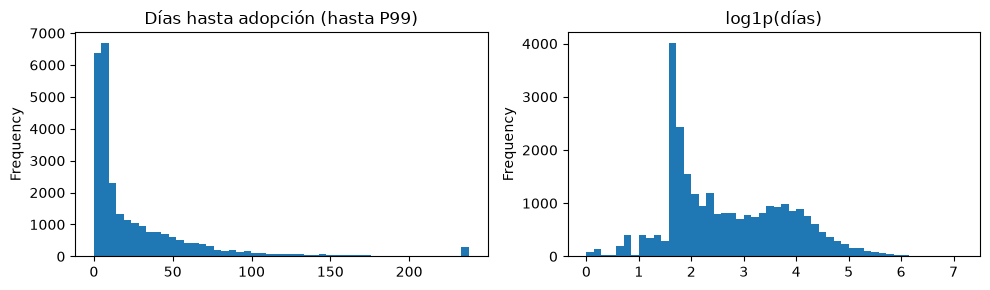

In [12]:
print(y["y_outcome"].value_counts())
print("\nAdoptados (y_log_days definido):", y["y_log_days"].notna().sum())

days = df.loc[y["y_outcome"] == "Adoption", "time_in_shelter_days"]
print(f"Asimetría de los días: {days.skew():.1f} -> con log1p: {np.log1p(days).skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
days.clip(upper=days.quantile(0.99)).plot.hist(bins=50, ax=ax[0], title="Días hasta adopción (hasta P99)")
y["y_log_days"].dropna().plot.hist(bins=50, ax=ax[1], title="log1p(días)")
plt.tight_layout()
plt.show()

- `y_outcome`: clasificación multiclase con 5 clases. `Adoption` tiene 27 073 animales (42,5 %). `Other` agrupa 834 filas (`Died`, `Disposal`, `Missing`, `Relocate`) y `Rto-Adopt` cuenta como `Adoption`.
- `y_log_days`: `log1p` de los días, solo para adoptados. La asimetría baja de 7,0 a 0,45. Para volver a días: `np.expm1`.

## 4. Guardar

Se guarda la tabla con las variables nuevas y los objetivos. Las variables aún no están en números: eso lo hace el preprocesador en cada fold.

In [13]:
dev_features = pd.concat([feats[["animal_id_intake"] + FEATURES], y], axis=1)
dev_features.to_csv("../data/processed/dev_features.csv", index=False)
print(dev_features.shape)

(63681, 25)


## 5. Ejemplo: preprocesar con folds

El preprocesador aprende con el train de cada fold (`fit`) y a la validación solo se le aplica (`transform`). Ejemplo con el primer fold:

In [14]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(cv.split(feats, groups=feats["animal_id_intake"]))

prep = build_preprocessor()
X_train = prep.fit_transform(feats.iloc[train_idx][FEATURES])   # aprende con train
X_val = prep.transform(feats.iloc[val_idx][FEATURES])           # solo aplica lo aprendido

print("Train:", X_train.shape, "| Validación:", X_val.shape)

col = list(prep.get_feature_names_out()).index("num__age_days")
print(f"age_days estandarizada -> train: media {X_train[:, col].mean():.2f}, desviación {X_train[:, col].std():.2f}"
      f" | validación: media {X_val[:, col].mean():.2f}, desviación {X_val[:, col].std():.2f}")

Train: (50952, 84) | Validación: (12729, 84)
age_days estandarizada -> train: media 0.00, desviación 1.00 | validación: media -0.01, desviación 0.98


La validación no queda con media 0 y desviación 1: se transforma con la media y la desviación del train.

Con un `Pipeline`, sklearn hace esto solo en cada fold:

```python
data = pd.read_csv("../data/processed/dev_features.csv")
pipe = Pipeline([("prep", build_preprocessor()), ("model", modelo)])
cross_val_score(pipe, data[FEATURES], data["y_outcome"], groups=data["animal_id_intake"], cv=cv)
```

Para regresión, filtrar `data["y_outcome"] == "Adoption"` y usar `y_log_days`.